# Lesson 6 · The most beautiful formula turns for you — Euler's formula e^{iθ}=cosθ+isinθ and the FFT's twiddle factor

**Learning goals**
1. Understand Euler's formula `e^{iθ} = cosθ + i·sinθ` — the complex exponential is a rotation on the unit circle, with real part = cosθ and imaginary part = sinθ
2. Check special angles such as θ=0, π/2, π, 3π/2 by hand, confirming that the real and imaginary parts match the trig functions row by row
3. Implement `twiddle(k, n, N) = e^{-2πikn/N}`, and be able to explain the three parameters k / n / N with a "clock face" picture
4. Confirm that the twiddle factor always has magnitude 1 and that its phase decreases evenly, in steps of `-2π/N`
5. Build the intuition: in L37–L39 the twiddle factors get lined up into the DFT / FFT (you don't need to write the matrix in this lesson)

**Why it matters for Aurora**: the core of the DFT is the twiddle factor `e^{−2πi·k·n/N}`, and the FFT runs entirely on it. Understand it, and rewriting the FFT in L37-L39 will rest on solid ground.

← **Previous lesson** [L05 · The magnitude and phase of a complex number](L05_complex_numbers.en.ipynb)

> Last lesson covered **the magnitude and phase of a complex number**: an ID card for every frequency, reading magnitude and phase out of a complex number — the native language of the FFT.
> This lesson explores **Euler's formula e^{iθ}=cosθ+isinθ**.

## The story: one line of numbers packs in everything on the circle

Ever wondered why Euler's formula e^{iθ} is called "the most beautiful formula in mathematics"?

The reason is simple: **a single real number θ pins down a complete position on the circle.**

The point at angle θ on the unit circle has two coordinates: (cos θ, sin θ). The ordinary way of writing it needs two slots.
Euler's stroke of genius: merge those two slots into one complex number:

```
e^{iθ} = cos θ + i·sin θ
```

This is more than shorthand — it reveals the algebraic structure of rotation:
- **Multiplication = rotation**: `e^{iα} × e^{iβ} = e^{i(α+β)}` (adding angles = combining two rotations)
- **nth power = n times the rotation**: `(e^{iθ})^n = e^{inθ}`

The core operation of the DFT is multiplying the signal by a column of "twiddle factors", projecting it onto each frequency direction one at a time. The twiddle factor is just `W = e^{−2πi·k·n/N}`. Once you understand e^{iθ}, the DFT stops being mysterious.

(Where exactly does "multiplication = rotation" come from? It isn't decreed out of thin air — right below we derive it step by step and check it with concrete numbers.)

## Why does "multiplication = rotation" hold? — finishing with the angle-addition formulas

The property above:
```
e^{iα} × e^{iβ} = e^{i(α+β)}
```
is not a rule that pops out of nowhere; it can be derived from Euler's formula itself. Let's derive it ourselves (even if you've completely forgotten the "angle-addition formulas", we'll review them below).

**Step 1**: expand both complex numbers using Euler's formula —
```
e^{iα} × e^{iβ} = (cosα + i·sinα)(cosβ + i·sinβ)
```

**Step 2**: multiply out like two ordinary pairs of parentheses (remember `i × i = -1`, the key to complex multiplication):
```
= cosα·cosβ + i·cosα·sinβ + i·sinα·cosβ + i²·sinα·sinβ
= (cosα·cosβ − sinα·sinβ) + i·(sinα·cosβ + cosα·sinβ)
```

**Step 3**: now we call in the high-school "angle-addition formulas" to the rescue (forgot them? no problem — here's the standard form):
```
cos(α+β) = cosα·cosβ − sinα·sinβ
sin(α+β) = sinα·cosβ + cosα·sinβ
```
Substitute these two into the parentheses from the previous step, and you get exactly:
```
= cos(α+β) + i·sin(α+β) = e^{i(α+β)}
```

Multiply two complex numbers, and the real and imaginary parts that come out are precisely — no more, no less — the cos and sin of the summed angle. That's what's really going on behind "multiplication = rotation": not a coincidence, but the angle-addition formulas at work. (This also answers another question in passing: why does an imaginary exponent still obey the real-exponent law `a^m·a^n=a^{m+n}`? Because once you define it as `cosθ+i·sinθ`, the algebra shows that it holds.)

Now let's check it with concrete numbers and see for ourselves:

In [1]:
# Aurora matplotlib bootstrap
from pathlib import Path
import sys

_root = None
_cwd = Path.cwd().resolve()
for _candidate in (_cwd, *_cwd.parents):
    if (_candidate / '_matplotlib_bootstrap.py').exists():
        _root = _candidate
        break
if _root is None:
    _notebooks_dir = _cwd / 'notebooks'
    if _notebooks_dir.exists():
        for _found in _notebooks_dir.rglob('_matplotlib_bootstrap.py'):
            _root = _found.parent
            break
if _root is not None and str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from _matplotlib_bootstrap import apply as _aurora_mpl_apply
_aurora_mpl_apply()


In [ ]:
import numpy as np

alpha, beta = np.radians(30), np.radians(60)
z1 = np.exp(1j * alpha)
z2 = np.exp(1j * beta)
product = z1 * z2

print(f'z1 = e^(i·30°) = {z1:.4f}   (angle {np.degrees(np.angle(z1)):.1f}°)')
print(f'z2 = e^(i·60°) = {z2:.4f}   (angle {np.degrees(np.angle(z2)):.1f}°)')
print(f'z1 * z2       = {product:.4f}   (angle {np.degrees(np.angle(product)):.1f}°)')
print()
print('30° + 60° = 90°, the angle of z1*z2 really is 90°:', np.isclose(np.angle(product), np.pi/2))
print(f'e^(i·90°) itself = {np.exp(1j*np.pi/2):.4f}   the two should be exactly equal:', np.allclose(product, np.exp(1j*np.pi/2)))


## 1. Assemble e^{iθ} by hand and check that it equals np.exp(iθ)

Let's start from geometry, without any formula:

The point on the unit circle at angle θ has coordinates (cos θ, sin θ).

Now "pack" these two numbers into one complex number: `manual = cos θ + i·sin θ`

Euler's formula asserts: `np.exp(1j * theta) == manual`

Checking is easy — run the cell below and confirm the two columns of numbers are identical. This is no coincidence; it's a mathematical theorem.

> **Main-path contract**: this lesson uses `e^{iθ} = cosθ + i·sinθ` as a **definition/convention** (the next cell, "proof or definition?", is honest about this).
> If you want the optional series-matching derivation, expand the fold below; **skipping it won't affect the twiddle exercise**.

<details>
<summary><b>Optional: how the Taylor series lines up with cos / sin</b></summary>

Take the Taylor expansion $e^x = 1 + x + x^2/2! + \cdots$ and substitute $x = i\theta$: the real part converges to the cos series and the imaginary part to the sin series.
L06 doesn't require you to derive this step; when L37 derives the DFT it simply uses the result of Euler's formula.

</details>

(Is "running code to check it" just proving something with itself? — A perfectly reasonable doubt; the next cell comes clean about it.)

## Interlude: is e^{iθ} "proved" or "defined"?

Your confusion is entirely reasonable: in high school, a power means "multiply it by itself some number of times" — e cubed is e×e×e. But e to the power i? "Multiply it by itself i times" isn't an operation you can actually carry out; the high-school definition breaks down here.

Here's what actually happened: mathematicians later **generalized** the idea of "raising to a power" from "repeated multiplication" into something more general, and the generalization wasn't arbitrary — they wanted the old rules (such as `e^a · e^b = e^{a+b}`) to keep holding under the new definition. It turned out there's only one self-consistent way to generalize: define `e^{iθ}` as "the point you land on after turning θ radians around the unit circle", i.e. `cosθ + i·sinθ`.

In other words: `e^{iθ} = cosθ + i·sinθ` is less "a theorem that was proved" than "the definition mathematicians carefully chose, the only one that lets the old exponent laws keep working". The Taylor expansion (write e^x as 1+x+x²/2!+... and substitute x=iθ) is one historical route for checking that this definition is self-consistent, but not the only one, and not something this lesson requires you to master — feel free to skip it for now and come back before L37 if you have time.

So is "running code to check it" just proving something with itself? — Your instinct is right: inside, `np.exp(1j*theta)` really is computed as `cosθ+i·sinθ`, so strictly speaking this step "confirms that numpy faithfully follows the convention", rather than proving the theorem from scratch. It's like using a calculator to check that the formula "speed = distance / time" computes correctly, not reinventing the law of physics — the real proof is left for more advanced math courses. Here we're just confirming that two routes (the geometric definition vs. numpy's implementation) produce the same number.

## Checking special angles: Euler's formula, three views

The three code cells below look at the same thing from three sides — **no need to reread long text for each one**; each cell has just one thing to watch:

1. **This cell**: hand-packed `cos/sin` vs `np.exp` — are they equal everywhere, and is the magnitude always 1?
2. **The next cell**: only the coordinate rotation at the four special angles 0, π/2, π, 3π/2.
3. **The cell after that**: a denser table of angles, checking that the three columns line up row by row.

In [ ]:
import numpy as np
theta = np.linspace(0, 2*np.pi, 9)
manual = np.cos(theta) + 1j*np.sin(theta)
print('matches np.exp(iθ):', np.allclose(manual, np.exp(1j*theta)))
print('every point has magnitude 1:', np.allclose(np.abs(manual), 1.0))

## Hands-on observation: just the four special angles

**What to look for in this cell**: going 0 → π/2 → π → 3π/2, how the real and imaginary parts cycle through 0 and ±1 (the point hops through the four quadrants of the unit circle).

In [ ]:
import numpy as np

angles = np.array([0, np.pi/2, np.pi, 3*np.pi/2])
z = np.exp(1j * angles)

print('angle =', np.round(angles, 3))
print('real part cos =', np.round(z.real, 3))
print('imag part sin =', np.round(z.imag, 3))
print('complex z =', np.round(z, 3))


## Code experiment: a denser table of angles

**What to look for in this cell**: with denser sampling, do the three columns (cos / sin / exp) still match row by row — confirming it isn't just a lucky coincidence at the four special angles.

In [5]:
import numpy as np

angles = np.linspace(0, 2*np.pi, 9)
for theta in angles:
    z = np.exp(1j * theta)
    print(f'theta={theta:5.2f} | cos={z.real:6.3f} | sin={z.imag:6.3f} | z={z.real:6.3f}{z.imag:+6.3f}j')


theta= 0.00 | cos= 1.000 | sin= 0.000 | z= 1.000+0.000j
theta= 0.79 | cos= 0.707 | sin= 0.707 | z= 0.707+0.707j
theta= 1.57 | cos= 0.000 | sin= 1.000 | z= 0.000+1.000j
theta= 2.36 | cos=-0.707 | sin= 0.707 | z=-0.707+0.707j
theta= 3.14 | cos=-1.000 | sin= 0.000 | z=-1.000+0.000j
theta= 3.93 | cos=-0.707 | sin=-0.707 | z=-0.707-0.707j
theta= 4.71 | cos=-0.000 | sin=-1.000 | z=-0.000-1.000j
theta= 5.50 | cos= 0.707 | sin=-0.707 | z= 0.707-0.707j
theta= 6.28 | cos= 1.000 | sin=-0.000 | z= 1.000-0.000j


## A "feel" before the code: what exactly is twiddle?

The upcoming exercise has you write a function called `twiddle(k, n, N)`. Before you type any code, build a mental picture first — otherwise it's easy to end up with "I can type this line, but I have no idea what I'm computing".

**Picture it as a round clock face**:
- `N`: how many tick marks the face is divided into (say N=8: 8 tick marks spaced evenly around the circle).
- `n`: which tick time has advanced to (which slot on the face you're standing on right now).
- `k`: the hand's "speed setting" — the bigger k is, the more slots the hand skips with each step (k=1 moves 1 slot per step, k=2 moves 2 slots per step, turning faster).

Multiply `k` and `n` together, then divide by `N`, and you get "for this hand with speed k, after n steps, what fraction of full turns has it gone through". That's what the angle `-2π·k·n/N` means; the minus sign just says this hand moves clockwise (the common-misconceptions cell next covers this specifically).

**A mini example with no DFT jargon (N=4, k=1)**: the face has only 4 slots and the hand moves 1 slot per step, so for n=0,1,2,3 the hand should point at 0°, -90°, -180°, -270° respectively. Let's just compute it:

In [ ]:
import numpy as np

# Mini example: a clock face with N=4 slots, hand speed k=1, taking n=0,1,2,3 steps
N, k = 4, 1
for n in range(N):
    angle = -2 * np.pi * k * n / N
    print(f'n={n} | should point at {np.degrees(angle):.0f}° | position = {np.exp(1j*angle):.3f}')


So what do words like "frequency index", "projecting onto a frequency direction", "inner product", and "DC component" mean? — Honestly: those words belong to the DFT lesson in L37. This lesson deliberately borrows them early to make the connections smoother, but you **don't need** to fully understand them now. If you really want a picture: imagine holding several "searchlights" that spin at different speeds (one per k), all shining on the same signal — if one light's speed happens to match the signal's own "rhythm", the signal looks especially "lined up" in that light (which is exactly what "projection" and "inner product" will do later); the k=0 light doesn't spin at all and only shows the signal's average brightness, which is what we'll later call the "DC component".

In this lesson you only need to remember one sentence: **twiddle is "where on the circle hands spinning at different speeds have got to at different moments"** — compute that point's coordinates correctly and today's task is done. The "how is it used later" questions — projection, inner product, DC component — are left for L37.

## ⚠️ Common misconceptions

> Don't treat the minus sign and the `k·n` product in the twiddle factor `e^{−2πikn/N}` as "an arbitrary convention". The minus sign means the DFT projects in the **clockwise** direction; `k·n/N` is "what fraction of full turns it has reached" — the larger k, the faster it turns; the larger n, the farther it has gone. Change any one of them, and you project onto the wrong frequency.

> In clock terms: `N` is the total number of tick marks on the face, `k` is how many slots the hand jumps per step (its speed setting), and `n` is how many steps it has taken (time). `k·n/N` computes "what fraction of full turns it has gone through", and the minus sign says the hand runs clockwise — the newly added cell just above has a fuller "speed-setting hand" picture if you want to scroll back.

## 2. ✏️ Implement the FFT twiddle factor `twiddle(k, n, N)`

`W = e^{−2πi·k·n/N}`

**Line of reasoning**:
1. Compute the phase angle φ: `θ = -2π · k · n / N` (k is the frequency index, n is the sample index, N is the total number of DFT points)
2. Take the complex exponential of the phase angle: `np.exp(1j * θ)` = `cosθ + i·sinθ`; the result always has magnitude r = 1 and lies on the unit circle
3. Note that the minus sign is dictated by the definition of the DFT and can't be dropped; `k · n / N` controls what fraction of a full turn this rotation covers

**Reference input and output**: `twiddle(k=1, n=1, N=8)` = `exp(-2πi/8)` ≈ `0.707 - 0.707j`
(angle about **−45°**, which can also be read as 315°; `np.angle` reports the shortcut within (−π, π], so you'll often see negative angles — the parameter experiment later runs into phase wrap-around.)

> 💡 Need a hint? After finishing the exercise you can consult the reference implementation in the `solutions/` folder.


### Before writing code, fill in the variable table

Be clear on three things before writing `twiddle`:
- Input: `k` (frequency index), `n` (time sample index), `N` (total DFT length)
- Key steps: compute the phase `-2π·k·n/N`, then take its complex exponential `np.exp(...)`
- Return: a complex number with magnitude 1 and argument `-2πkn/N`

In [ ]:
def twiddle(k, n, N):
    # ✏️ TODO: return e^{-2πi·k·n/N}
    raise NotImplementedError("TODO: return e^{-2πi·k·n/N} — the complex value of the twiddle factor")


In [ ]:
import numpy as np
try:
    assert abs(twiddle(0, 0, 8) - 1) < 1e-12, 'k·n=0 should give 1'
    assert abs(abs(twiddle(3, 5, 8)) - 1) < 1e-12, 'magnitude should be 1'
    _ref = np.exp(-2j * np.pi * 1 * 1 / 8)
    assert abs(twiddle(1, 1, 8) - _ref) < 1e-12, 'wrong phase direction: the formula is e^{-2πikn/N}, the minus sign is required'
    print('✅ Passed: you have a grip on the FFT twiddle factor.')
except (NotImplementedError, TypeError):
    print('⬜ Implement twiddle(k, n, N) first, then run this check cell')


## 3. Draw the unit circle

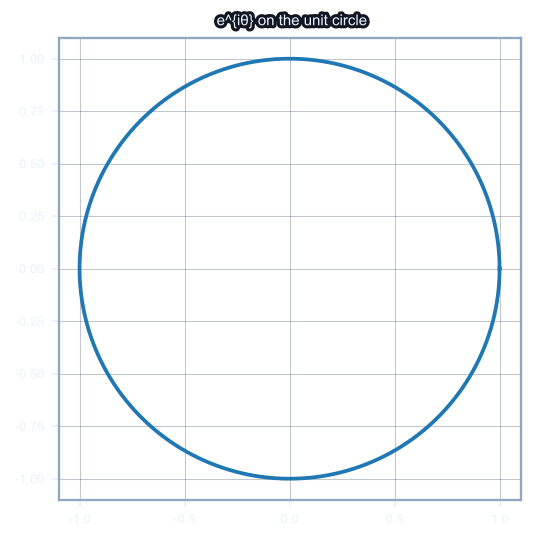

In [9]:
import numpy as np, matplotlib.pyplot as plt
fine = np.exp(1j*np.linspace(0, 2*np.pi, 200))
plt.figure(figsize=(4,4))
plt.plot(fine.real, fine.imag); plt.gca().set_aspect('equal')
plt.grid(True, alpha=.3); plt.title('e^{iθ} on the unit circle'); plt.show()

**🔗 Aurora connection (one line to remember for now)**: DFT = the inner product of the signal with "a column of twiddles"; each frequency k corresponds to one column of twiddle factors.
In the repo, `dft()` in `src/aurora/audio/transforms.py` does exactly this (the implementation builds the full matrix, which is mathematically equivalent to this lesson's point-by-point `twiddle(k,n,N)`).
L37–L39 rewrite the naive O(N²) version into an O(N log N) FFT — **the definition of the twiddle factor stays the same; what changes is the order of computation**.

In [10]:
angles = np.linspace(0, 2*np.pi, 5)
for theta in angles:
    z = np.exp(1j*theta)
    reconstructed = np.cos(theta) + 1j*np.sin(theta)
    print(f'theta={theta:.2f} | exp={z:.2f} | cos+i sin={reconstructed:.2f} | match={np.allclose(z, reconstructed)}')


theta=0.00 | exp=1.00+0.00j | cos+i sin=1.00+0.00j | match=True
theta=1.57 | exp=0.00+1.00j | cos+i sin=0.00+1.00j | match=True
theta=3.14 | exp=-1.00+0.00j | cos+i sin=-1.00+0.00j | match=True
theta=4.71 | exp=-0.00-1.00j | cos+i sin=-0.00-1.00j | match=True
theta=6.28 | exp=1.00-0.00j | cos+i sin=1.00-0.00j | match=True


## Heads-up: why does the printed angle suddenly "jump"?

The parameter experiment below prints a list of angles. The first few rows dutifully drop by 45° each time, but at a certain row the number suddenly goes from near -180° to about +135°, looking as if it "turned back". **This is not a bug, and it doesn't mean your twiddle is wrong** — it comes from the "reading habits" of the `np.angle` function itself. Knowing it in advance means you won't, like students who got stuck here, go back and doubt your own code.

An everyday analogy: a wall clock has only 12 marks. When the hand keeps going past "11 o'clock", you don't see "12.5 o'clock" — it wraps around to "12" and then near "1". The face's reading range is cyclic. `np.angle` is the same: it only reports readings in the range **(−180°, +180°]** (that is, (−π, π]). A hand that has actually turned to -225° is outside that range, so it gets "folded" back and reported as +135° (-225° + 360° = 135°, still the same direction) — this is called "phase wrap".

`np.unwrap` "straightens out" these folded angles again: it checks whether two neighboring readings differ by a fake jump of more than 180°, and if so, automatically adds/subtracts a whole multiple of 360°, stitching the sequence back into a continuous change. `np.diff` only does "subtract neighbors" — it computes the difference between adjacent numbers and does no wrap correction at all, so you must unwrap first and then diff to see the true pattern "every step is -45°".

The code below doesn't depend on your `twiddle` implementation; it demonstrates the wrap-around directly with `np.exp`. Run it and see:

In [ ]:
import numpy as np

# Angles that really decrease continuously (simulating the phases twiddle should have at k=1, N=8)
raw_angles = np.linspace(0, -7 * 2*np.pi/8, 8)
reported = np.angle(np.exp(1j * raw_angles))  # np.angle only reports within (-π, π]

print('true, continuously decreasing angles (rad):', np.round(raw_angles, 3))
print('angles np.angle actually reports:          ', np.round(reported, 3))
print()
print('diff without unwrap (one fake jump):', np.round(np.diff(reported), 3))
print('unwrap then diff (step steady at -2π/8):', np.round(np.diff(np.unwrap(reported)), 3))


## Parameter experiment: watch the phase decrease evenly

Fix `k=1`, let `n` run from 0 to N-1, and print the phase of each twiddle factor (`np.angle`, in radians), confirming that the phase decreases evenly in steps of `-2π/N`:

```python
N = 8
for n in range(N):
    w = twiddle(k=1, n=n, N=N)
    print(f'n={n} | angle={np.angle(w):.4f} rad ({np.degrees(np.angle(w)):.1f}°)')
# Expected: each row's angle differs by -45° (= -2π/8 ≈ -0.785 rad)
```

Then change N to 4 (step becomes -90°) or 1024 (step shrinks to about -0.35°) and get a feel for how N controls the frequency resolution.

> **Reminder**: if you've already read the newly added note in the previous cell, you know that around n=5 there will be a +135° jump that looks like "going up instead of down" — that's caused by `np.angle`'s reading range, not a mistake in `twiddle`.
>
> **What does "frequency resolution" mean?** The larger N is, the smaller the angle difference between two neighboring frequency ticks, so the closer together — the finer — the two neighboring frequencies the DFT can tell apart (resolve). That's the literal meaning of "resolution" — just as a ruler with denser tick marks can measure smaller differences.

In [ ]:
import numpy as np

try:
    # Learning goal #4: confirm the twiddle phase decreases evenly, in steps of -2π/N
    N = 8
    for n in range(N):
        w = twiddle(k=1, n=n, N=N)
        print(f'n={n} | angle={np.angle(w):.4f} rad ({np.degrees(np.angle(w)):.1f}°)')

    phases = [np.angle(twiddle(1, n, 8)) for n in range(8)]
    diffs = np.diff(np.unwrap(phases))
    assert np.allclose(diffs, -2 * np.pi / 8), 'phase steps are uneven — check your twiddle implementation'
    print(f'\n✅ Phase steps are even: {-2*np.pi/8:.4f} rad per step (= -2π/8)')
    print('Now change N to 4 or 1024 and get a feel for how N controls frequency resolution.')
except (NotImplementedError, TypeError):
    print('⬜ Implement twiddle(k, n, N) first, then run the phase experiment')


## 🎯 The payoff later (Future Payoff)

The **twiddle factor `twiddle(k, n, N)`** you assembled by hand today will show up again in **L37–L39 hand-written FFT / L43 STFT / L44 spectra** — every row of the DFT matrix is a string of twiddle factors. Weld "e^{iθ} is a rotation on the unit circle" into your intuition today, and you won't feel shaky when rewriting the FFT later.

## Wrap-up

You can now use `np.exp(1j*theta)` to compute the complex coordinates on the unit circle for any angle, and use `twiddle(k, n, N)` to compute the DFT twiddle factor e^(-2πikn/N). `twiddle` maps directly onto the logic of `dft()` in `transforms.py` in Aurora's audio core, and the FFT implementation in L37-L39 reuses it. Next lesson: **L07** stacking harmonics into a square wave — approximating a square wave by adding up sine waves, an intuitive demo of Fourier series synthesis, building the intuition that "every periodic signal is a sum of sine waves".

## Before the whiteboard math, a glance at the "negative-angle cheat sheet"

Hand-computing cos and sin of negative angles is the easiest place to crash, so spend 30 seconds memorizing two rules:

- `cos(−θ) = cos θ` — cosine is an "even function": its graph is symmetric left-to-right; make the angle negative and the cosine stays the same.
- `sin(−θ) = −sin θ` — sine is an "odd function": make the angle negative and the sine turns negative too.

An everyday analogy: start a watch hand at the 12 o'clock position and turn it 45° clockwise, then 45° counterclockwise. The hand's **left-right position** (horizontal coordinate, matching cos) is exactly the same both times, but its **up-down position** (vertical coordinate, matching sin) is exactly opposite — the clockwise turn drops below (negative), the counterclockwise turn tips above (positive).

Below we plot the four points the whiteboard challenge uses (0°, -45°, -90°, -135°) with their coordinates, so you can compare after computing by hand:

In [ ]:
import numpy as np, matplotlib.pyplot as plt

angles_deg = [0, -45, -90, -135]
angles_rad = np.radians(angles_deg)
pts = np.exp(1j * angles_rad)

circle = np.exp(1j * np.linspace(0, 2*np.pi, 200))
plt.figure(figsize=(4,4))
plt.plot(circle.real, circle.imag, alpha=.3)
plt.scatter(pts.real, pts.imag, color='red', zorder=5)
for deg, p in zip(angles_deg, pts):
    plt.annotate(f'{deg}°\n({p.real:+.2f},{p.imag:+.2f})', (p.real, p.imag),
                 textcoords='offset points', xytext=(8, 8))
plt.axhline(0, color='gray', lw=.5)
plt.axvline(0, color='gray', lw=.5)
plt.gca().set_aspect('equal'); plt.grid(True, alpha=.3)
plt.title('The four points used in the whiteboard challenge: 0°, -45°, -90°, -135°')
plt.show()


## ✏️ Whiteboard challenge: twiddle factors by hand (target: 8 minutes)

Cover the screen and answer on paper:

**Parameters**: N = 8 (an 8-point DFT), k = 1, n = 0, 1, 2, 3

**Question 1**: Write the twiddle factor formula `W(k,n,N) = e^{-2πi·k·n/N}`, substitute k=1, N=8, and simplify the exponent.

**Question 2**: Compute W(1, 0, 8), W(1, 1, 8), W(1, 2, 8), W(1, 3, 8) (polar or rectangular form both fine).
Hint: work them by hand first, then run the answer-check cell below; expand the fold below if you need a formula hint.

> Example of "polar" form: writing W(1,1,8) as "magnitude 1, angle -45°" counts as polar; writing `0.707 - 0.707j` is rectangular. Either one is fine. When hand-computing cos/sin of negative angles, you can first review the newly added "negative-angle cheat sheet" and four-point unit circle plot above.

<details><summary>Expand if you're stuck (try not to at first)</summary>

W(1,n,8) = e^{-iπn/4}; n=0→1, n=1→e^{-iπ/4}=cos(-45°)+i·sin(-45°)…

n=2 → e^{-iπ/2} = cos(-90°)+i·sin(-90°); n=3 → e^{-i3π/4} = cos(-135°)+i·sin(-135°) — for the sign pattern see the "negative-angle cheat sheet" above.

</details>

**Question 3**: In which direction are these 8 twiddle factors (n=0…7) evenly spread around the unit circle? Clockwise or counterclockwise?

**Question 4**: If k=0, what do all the twiddle factors W(0,n,N) equal? Why? (The answer-check cell below calls this case the "DC component" — DC is short for "Direct Current", borrowed by signal processing to mean the part that "doesn't change over time at all, leaving only the average"; in terms of the clock analogy earlier, it's "the hand whose speed is 0 and that never turns at all".)

When you've finished the derivation, run the cell below to check your answers.

In [ ]:
try:
    # ✏️ Answer-check cell
    import numpy as np

    N = 8

    # Q1+Q2: check the hand-computed twiddle factors
    print("Q1/Q2 ✅  W(1,n,8) = e^{-iπn/4}:")
    for n in range(4):
        w_theory = np.exp(-1j * 2 * np.pi * 1 * n / N)
        w_code   = twiddle(1, n, N)
        assert np.isclose(w_code, w_theory, atol=1e-10), f"n={n}: mismatch"
        deg = np.degrees(np.angle(w_theory))
        print(f"  n={n}: e^{{-iπ·{n}/4}} = {w_theory.real:+.4f}{w_theory.imag:+.4f}j  (phase {deg:+.1f}°)")

    # Q3: the 8 twiddle factors are evenly spread (unwrap first so ±π jumps don't corrupt the step)
    phases = np.unwrap([np.angle(twiddle(1, n, N)) for n in range(N)])
    diffs = np.diff(phases)
    step_deg = np.degrees(diffs[0])
    all_equal = np.allclose(diffs, diffs[0], atol=1e-10)
    assert all_equal, "phase steps are uneven"
    print(f"\nQ3 ✅  the 8 twiddle factors are evenly spread, step {step_deg:.1f}° ({'clockwise' if step_deg < 0 else 'counterclockwise'})")

    # Q4: with k=0 every factor is 1
    for n in range(N):
        w0 = twiddle(0, n, N)
        assert np.isclose(w0, 1.0, atol=1e-12), f"k=0,n={n}: expected 1, got {w0}"
    print(f"\nQ4 ✅  with k=0, W(0,n,N) = e^0 = 1 (no rotation at any time → DC component)")
    print("\n🎉 Twiddle-factor whiteboard challenge passed! The DFT's core operation now has a concrete picture in your head.")
except (NotImplementedError, TypeError):
    print('⬜ Finish the twiddle exercise above first, then run this answer-check cell')

In [ ]:
try:
    # ✏️ Lesson self-review
    l06_review = {
        "euler_formula_verified":   None,  # verified e^{iθ} = cosθ+i·sinθ? True/False
        "twiddle_implemented":      None,  # twiddle(k,n,N) implemented and assertions pass? True/False
        "rotation_intuition":       None,  # understand "multiplying by a complex number = rotation"? True/False
        "whiteboard_passed":        None,  # whiteboard challenge done on paper? True/False
    }

    unfilled = [k for k, v in l06_review.items() if v is None]
    assert not unfilled, f'not filled in yet: {unfilled}'
    weak = [k for k, v in l06_review.items() if v is False]
    if weak:
        print(f'⚠️  needs more work: {weak}')
    else:
        print('✅ L06 fully cleared! On to L07: everything is made of sines')
except (NotImplementedError, TypeError):
    print('⬜ Finish the TODO exercises above first, then run this cell')

---

→ **Next lesson** [L07 · Everything is made of sines](L07_fourier_intuition.en.ipynb)

> Next lesson covers **everything is made of sines**: synthesize a square wave by stacking sine harmonics, and build your Fourier intuition in one picture.